# 01 · Synthetic LED dataset

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/barak2rozenfeld/led-vision-lab/blob/master/notebooks/01_dataset.ipynb)

This notebook generates the **LED Vision Lab** synthetic dataset from scratch, counts what it actually
contains, and shows samples. It calls the project's own generator and statistics code, so the numbers here
are the same ones served by `GET /api/v1/dataset/stats` and shown in the web UI.

* **Generator:** `src/led_vision/synthetic/` driven by `configs/dataset/pcb_20k.yaml`
* **Size:** 20,000 scenes × 2 export sizes (128 px for classical / ML methods, 224 px for YOLO) = 40,000 images
* **Reproducibility:** fixed seed (77); the same seed and scene count reproduce the committed `artifacts/dataset/stats.json`
* **Runtime:** about 20 minutes on a free Colab CPU runtime (2 cores); set `SCENES = 4_000` for a quick look

## Setup
Clones the repository and installs the package when running in Colab; uses the local checkout otherwise.

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/barak2rozenfeld/led-vision-lab.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("led-vision-lab").exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir("led-vision-lab")
    !pip install -q -e .
elif Path.cwd().name == "notebooks":
    os.chdir("..")  # running locally: work from the repository root

sys.path.insert(0, str(Path.cwd() / "src"))  # importable without restarting the kernel
print("Working directory:", Path.cwd())

Working directory: C:\CursorProjects\led-vision-lab


## Parameters

In [2]:
SCENES = 20_000   # same as configs/dataset/pcb_20k.yaml; lower it (e.g. 4_000) for a quick run
SEED = 77         # same seed as the committed reports
WORKERS = os.cpu_count() or 2
DATASET = Path("data/generated_20k" if SCENES == 20_000 else f"data/generated_{SCENES}")

## Generate
Skipped when the dataset already exists. Every scene is rendered at 256 px and downsampled to each export size.

In [3]:
import json

if (DATASET / "metadata.csv").is_file():
    print(f"Reusing existing dataset in {DATASET}")
else:
    !{sys.executable} scripts/generate_dataset.py --config configs/dataset/pcb_20k.yaml --total {SCENES} --seed {SEED} --output {DATASET} --workers {WORKERS}

Reusing existing dataset in data\generated_20k


## What the dataset contains
`compute_dataset_stats` reads `metadata.csv` (one row per image, 40 fields) and counts each scene once.

In [4]:
from led_vision.synthetic.stats import compute_dataset_stats

stats = compute_dataset_stats(DATASET)
print(f"{stats['scenes']:,} scenes, {stats['images']:,} images, sizes: {stats['images_by_size']}")
print("state:", stats["counts"]["state"])
print("split:", stats["counts"]["split"])
print("distractor (false-positive) scenes:", stats["counts"]["false_positive"].get("True", 0))

20,000 scenes, 40,000 images, sizes: {'128': 20000, '224': 20000}
state: {'off': 10000, 'on': 10000}
split: {'train': 14000, 'test': 3000, 'val': 3000}
distractor (false-positive) scenes: 506


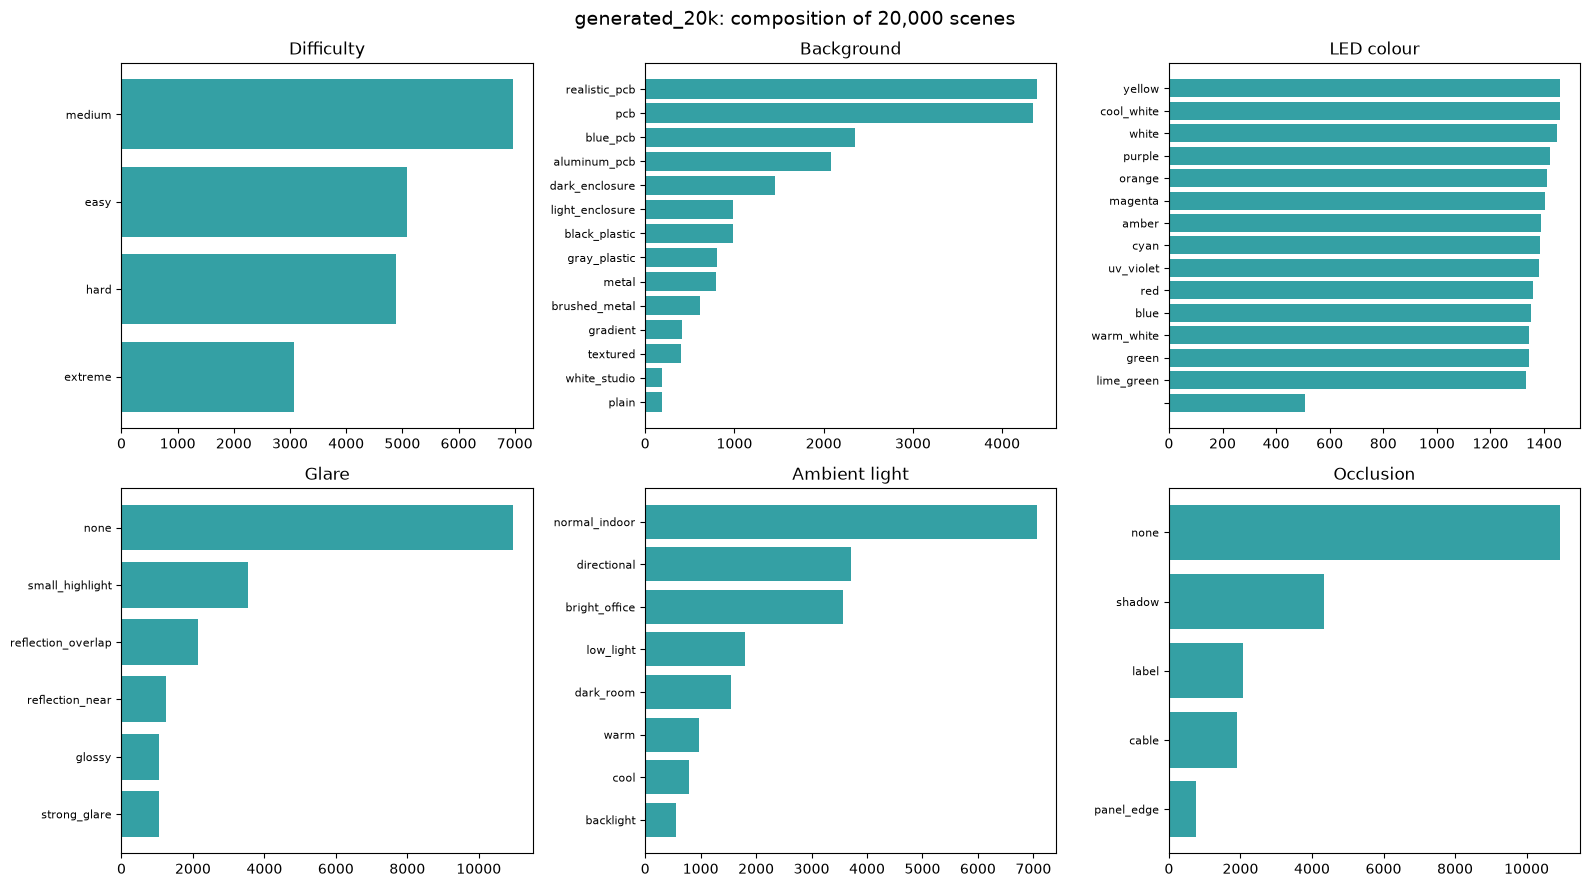

In [5]:
import matplotlib.pyplot as plt

panels = [("difficulty", "Difficulty"), ("background", "Background"), ("led_color", "LED colour"),
          ("glare_type", "Glare"), ("ambient_type", "Ambient light"), ("occlusion_type", "Occlusion")]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (field, title) in zip(axes.flat, panels):
    counts = stats["counts"][field]
    labels = list(counts)[::-1]
    ax.barh(labels, [counts[k] for k in labels], color="#34a0a4")
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"{DATASET.name}: composition of {stats['scenes']:,} scenes", fontsize=14)
fig.tight_layout()
plt.show()

### Is the label balanced inside every difficulty level?
If one difficulty level were mostly ON, a model could learn the difficulty cues instead of the LED state.

In [6]:
difficulties = ["easy", "medium", "hard", "extreme"]
cross = stats["cross_tabs"]["difficulty_x_state"]
for d in difficulties:
    on, off = cross.get(f"{d}|on", 0), cross.get(f"{d}|off", 0)
    print(f"{d:8s} ON {on:5d}  OFF {off:5d}  ({on / (on + off):.0%} ON)")

easy     ON  2550  OFF  2530  (50% ON)
medium   ON  3508  OFF  3461  (50% ON)
hard     ON  2434  OFF  2453  (50% ON)
extreme  ON  1508  OFF  1556  (49% ON)


## Reproducibility check
Compares these counts with the report committed to the repository.

In [7]:
committed = json.loads(Path("artifacts/dataset/stats.json").read_text(encoding="utf-8"))
if committed["counts"] == stats["counts"]:
    print("Identical to the committed report (commit", committed["provenance"]["git_commit"], ")")
else:
    diff = {k for k in stats["counts"] if stats["counts"][k] != committed["counts"].get(k)}
    print("Differs from the committed report in:", sorted(diff),
          "\n(expected when SCENES or SEED differ from the committed run)")

Identical to the committed report (commit 2b749a56d )


## Samples
Random ON and OFF scenes from the test split, with their difficulty.

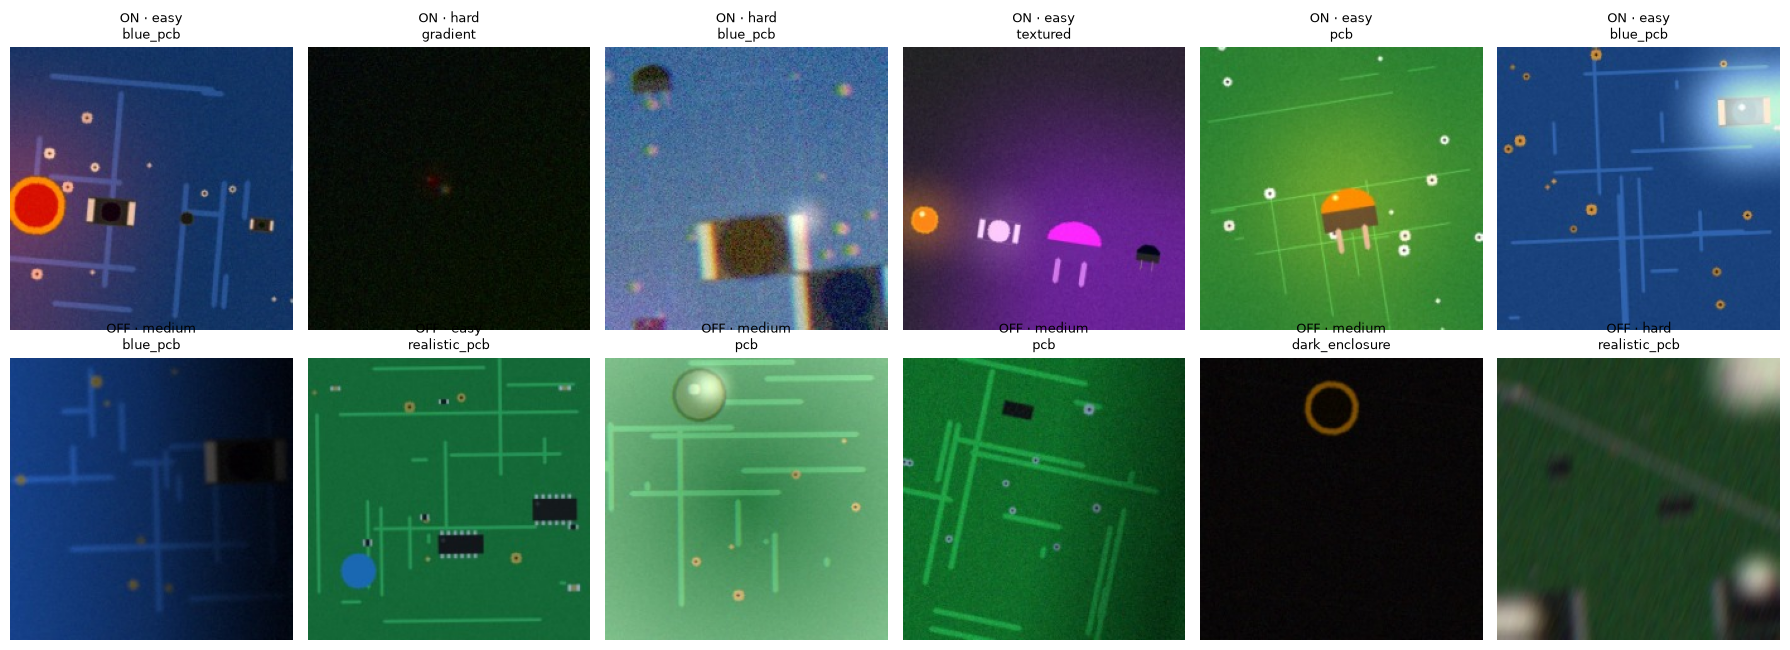

In [8]:
import csv
import random

import cv2

rows = [r for r in csv.DictReader((DATASET / "metadata.csv").open(encoding="utf-8"))
        if r["split"] == "test" and r["size"] == "224"]
rng = random.Random(0)
picks = rng.sample([r for r in rows if r["state"] == "on"], 6) + rng.sample([r for r in rows if r["state"] == "off"], 6)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax, r in zip(axes.flat, picks):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATASET / r["filepath"])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['state'].upper()} · {r['difficulty']}\n{r['background']}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## Design notes that matter for evaluation
* **No label leakage through glare.** Reflections are drawn on lit and unlit LEDs alike; only sensor bloom
  needs a lit LED, and its strength follows the LED brightness. An earlier version drew glare only on ON
  scenes, which let any detector "see" the label.
* **Ambient light does not dim emitters.** Ambient lighting scales reflected light only; a lit LED in a dark
  room stays bright.
* **Splits are fixed by the generator** (70 / 15 / 15). Calibration and training use `train`, model selection
  `val`, and every reported number comes from `test`.

Next: [02 · HSV baseline](02_hsv_baseline.ipynb).